In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression as LR

from dist import *
from utils import *
from theory import *

In [2]:
# figure formating
import seaborn as sns
custom_params = {"axes.spines.right": False,
                 "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['figure.dpi'] = 300

### 2-D Examples

In [3]:
asmp_error = 0.05 # asymptotic error bound
n_dim = 10
n_test = 4096

### Same H, Different h*

In [4]:
# linearly separable data
linear_dist = LinearSeparable(n=n_dim, k=2.0, seed=0)
dist_func = lambda m: linear_dist(m, noise_rate=asmp_error,
                                  both_classes=True)

# polynomial feature space
lh = polyexp_func(degree=2, distribution=dist_func)

In [5]:
# polynomial spearable data
poly_dist = PolySeparable(n=n_dim, degree=2, k=2.0, seed=0)
dist_func = lambda m: poly_dist(m, noise_rate=asmp_error,
                                both_classes=True)

# polynomial feature space
ph = polyexp_func(degree=2, distribution=dist_func)

No Regularization

(There might be some problem with using polynomial features     
for high-D data (implicit regularization); consider switching)

In [6]:
# linear logistic regression with polynomial features
# no regularization, h \in H (2nd order polynomial)
model = lambda: LR(penalty=None, solver='saga',
                   max_iter=1000, tol=0.001)

In [7]:
# estimate generalization error
# linear h + poly regression
np.random.seed(0)
cc_linear = ConvergenceCurve(lh, model, asmp_error=asmp_error, n_test=4096,
                           train_size = 2 ** np.arange(1, 13, 1), n_repeat=128)
train_size, error_linear, linear_sd = cc_linear.run()

# polynomial h + poly regression
np.random.seed(0)
cc_poly = ConvergenceCurve(ph, model, asmp_error=asmp_error, n_test=4096,
                           train_size = 2 ** np.arange(1, 13, 1), n_repeat=128)
train_size, error_poly, poly_sd = cc_poly.run()

In [8]:
# control comparison:
# linear h + linear regression model
n_control = 5
linear_dist = LinearSeparable(n=n_control, k=2.0, seed=42)
dist_func = lambda m: linear_dist(m, noise_rate=0.02,
                                  both_classes=True)

cc_ll = ConvergenceCurve(dist_func, model, asmp_error=0.02, n_test=4096,
                         train_size = 2 ** np.arange(1, 13, 1), n_repeat=128)
train_size, error_ll, ll_sd = cc_ll.run()

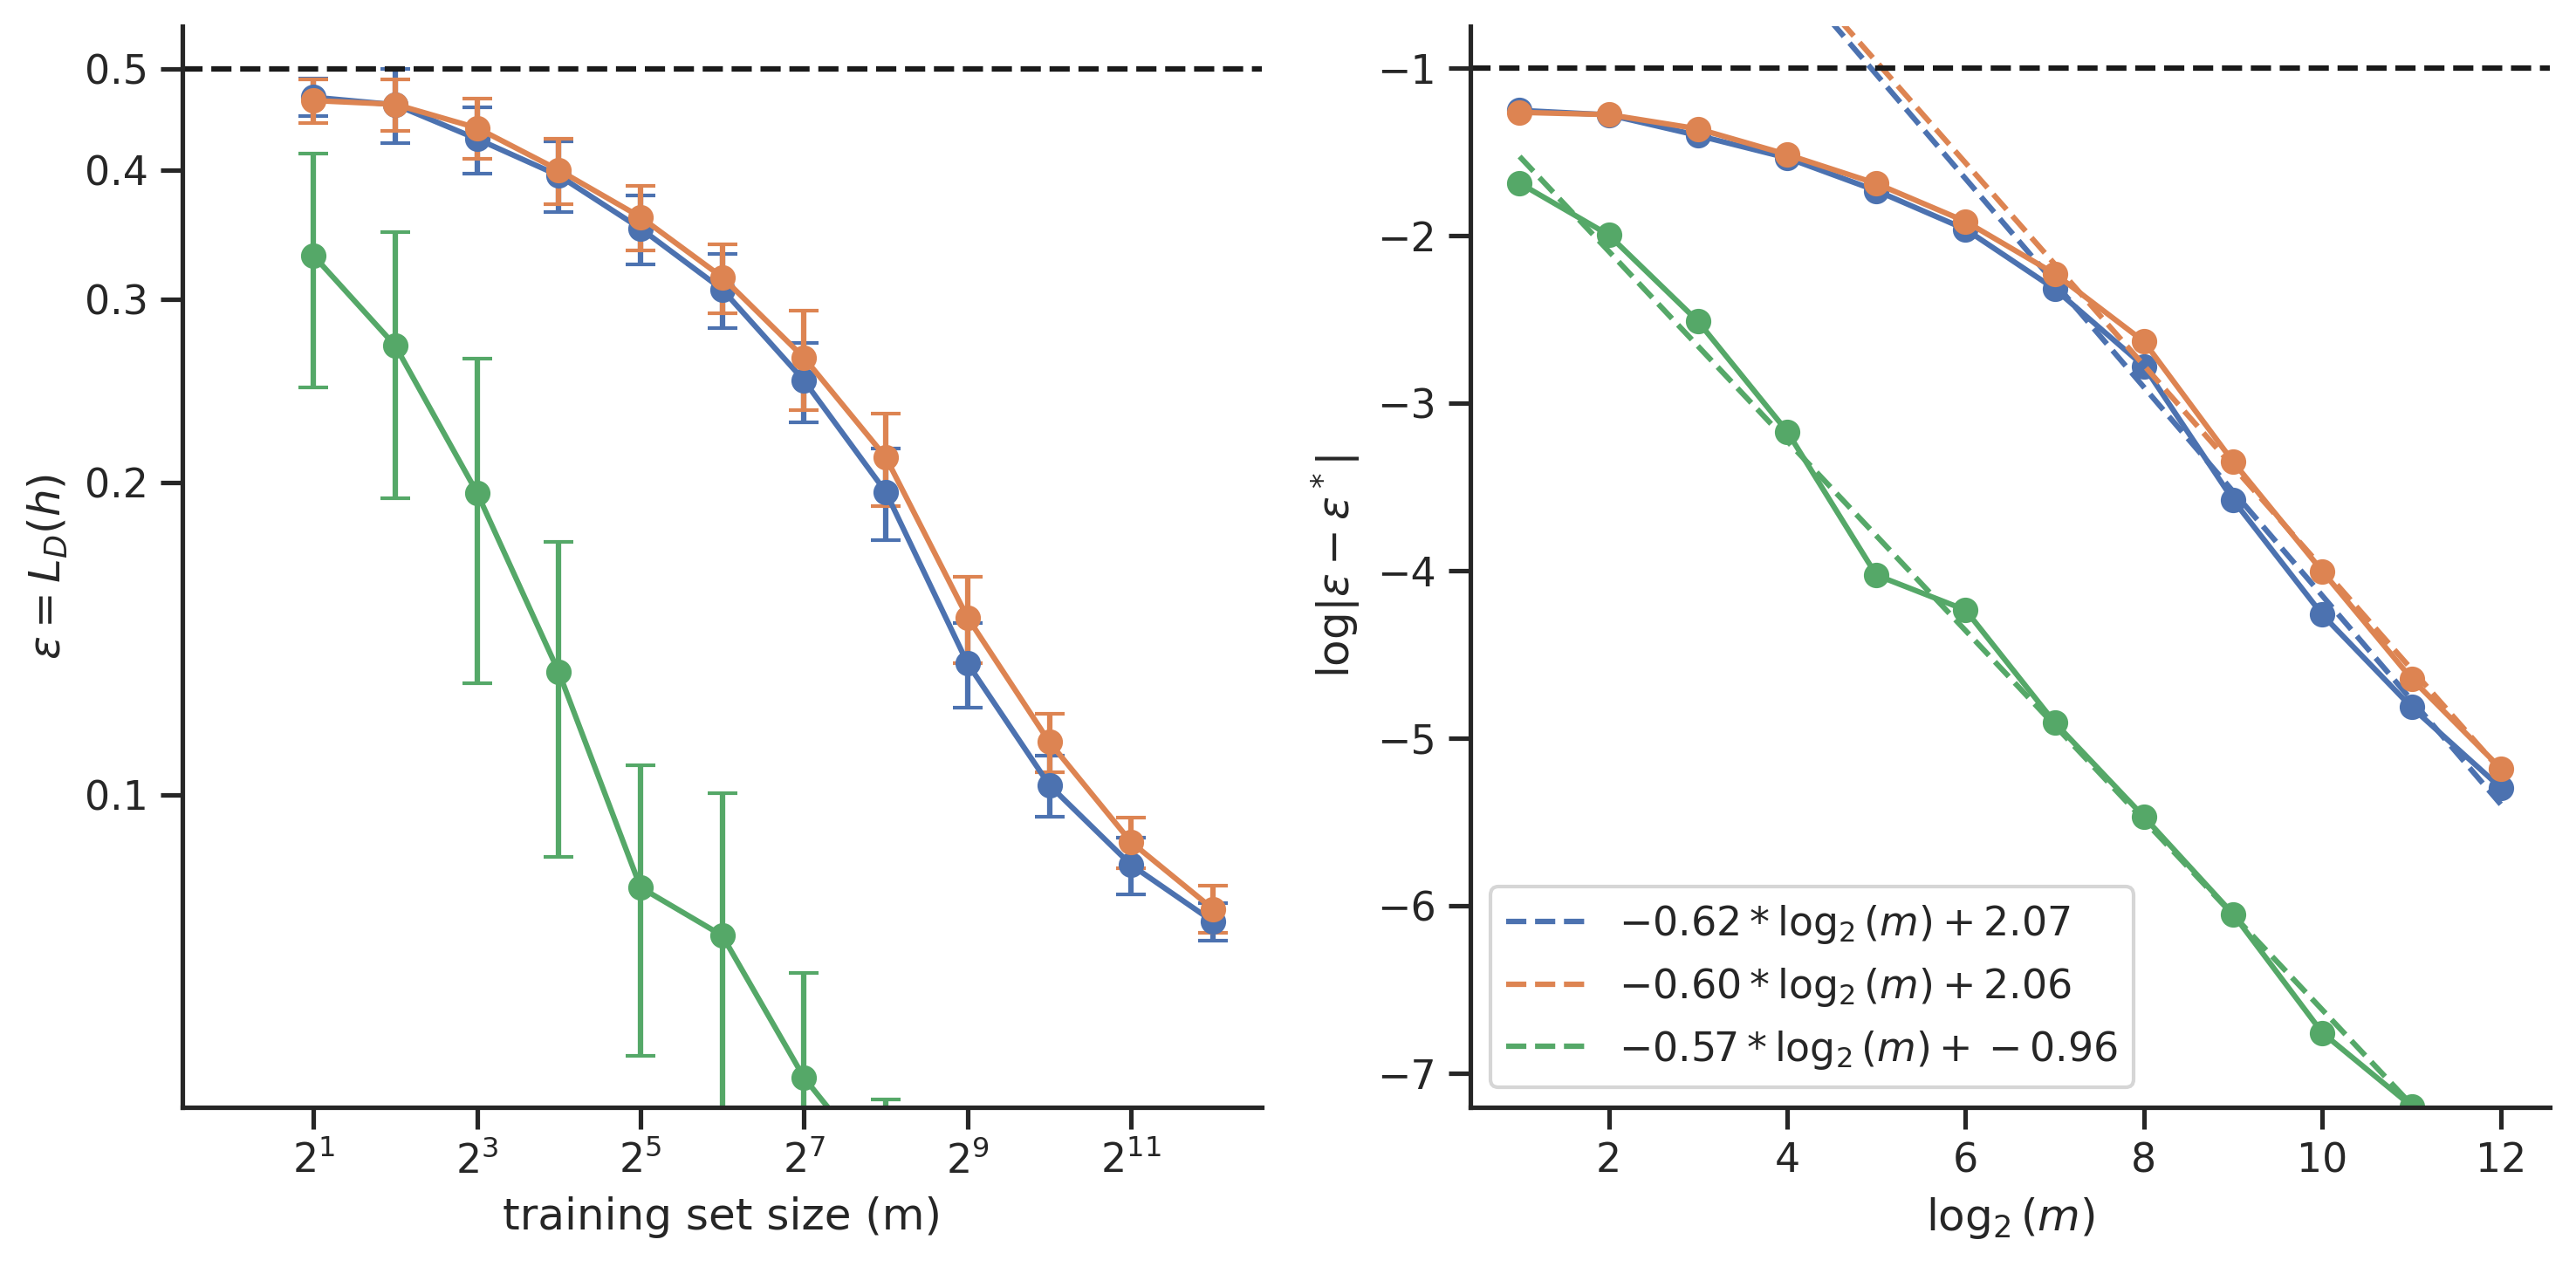

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

cc_linear.plot_error(axs[0])
cc_linear.plot_gap(axs[1], piecewise=True)

cc_poly.plot_error(axs[0])
cc_poly.plot_gap(axs[1], piecewise=True)

cc_ll.plot_error(axs[0])
cc_ll.plot_gap(axs[1], piecewise=False)

axs[0].axhline(y=0.5, color='k', linestyle='--')
axs[1].axhline(y=-1, color='k', linestyle='--')
axs[0].set_ylim([0.05, 0.55])
axs[1].set_ylim([-7.2, -0.75])

plt.tight_layout()
plt.savefig('./poly_curves_.pdf', bbox_inches='tight')
plt.show()

Note: the right panel has no error bars on purpose. It shows the *expected* generalization error $\mathbb{E}[\epsilon(m)]$, a deterministic function of $m$; its estimate can be made arbitrarily precise by running more simulation repeats. The error bars in the left panel (SD across repeats) show the run-to-run spread of $\epsilon$, not uncertainty in the curve.

Sparisity

(these are bit tricky as there is some small effect from implicit regularization from the optimizer, as the theoretical L_* ~= 0, but it cannot be reached in practice)

In [10]:
# linear logistic regression with polynomial features
# with L1 regularization, h \in H (2nd order polynomial)
model = lambda: LR(penalty='l1', solver='saga', C=0.2,
                   max_iter=1000, tol=0.0001)

In [11]:
# estimate generalization error
# linear h
np.random.seed(0)
cc_linear = ConvergenceCurve(lh, model, asmp_error=asmp_error, n_test=4096,
                           train_size = 2 ** np.arange(1, 13, 1), n_repeat=128)

cc_linear.run()

# polynomial h
np.random.seed(0)
cc_poly = ConvergenceCurve(ph, model, asmp_error=asmp_error, n_test=4096,
                           train_size = 2 ** np.arange(1, 13, 1), n_repeat=128)

cc_poly.run()

(array([   2,    4,    8,   16,   32,   64,  128,  256,  512, 1024, 2048,
        4096]),
 array([0.50088501, 0.49867249, 0.49268341, 0.47920609, 0.43114281,
        0.36598587, 0.28090668, 0.20226479, 0.1474247 , 0.11282921,
        0.09127998, 0.07817459]),
 array([0.02830648, 0.02828918, 0.0310704 , 0.03354246, 0.0321621 ,
        0.02809931, 0.02330553, 0.0158807 , 0.01258624, 0.00741276,
        0.00545289, 0.00404728]))

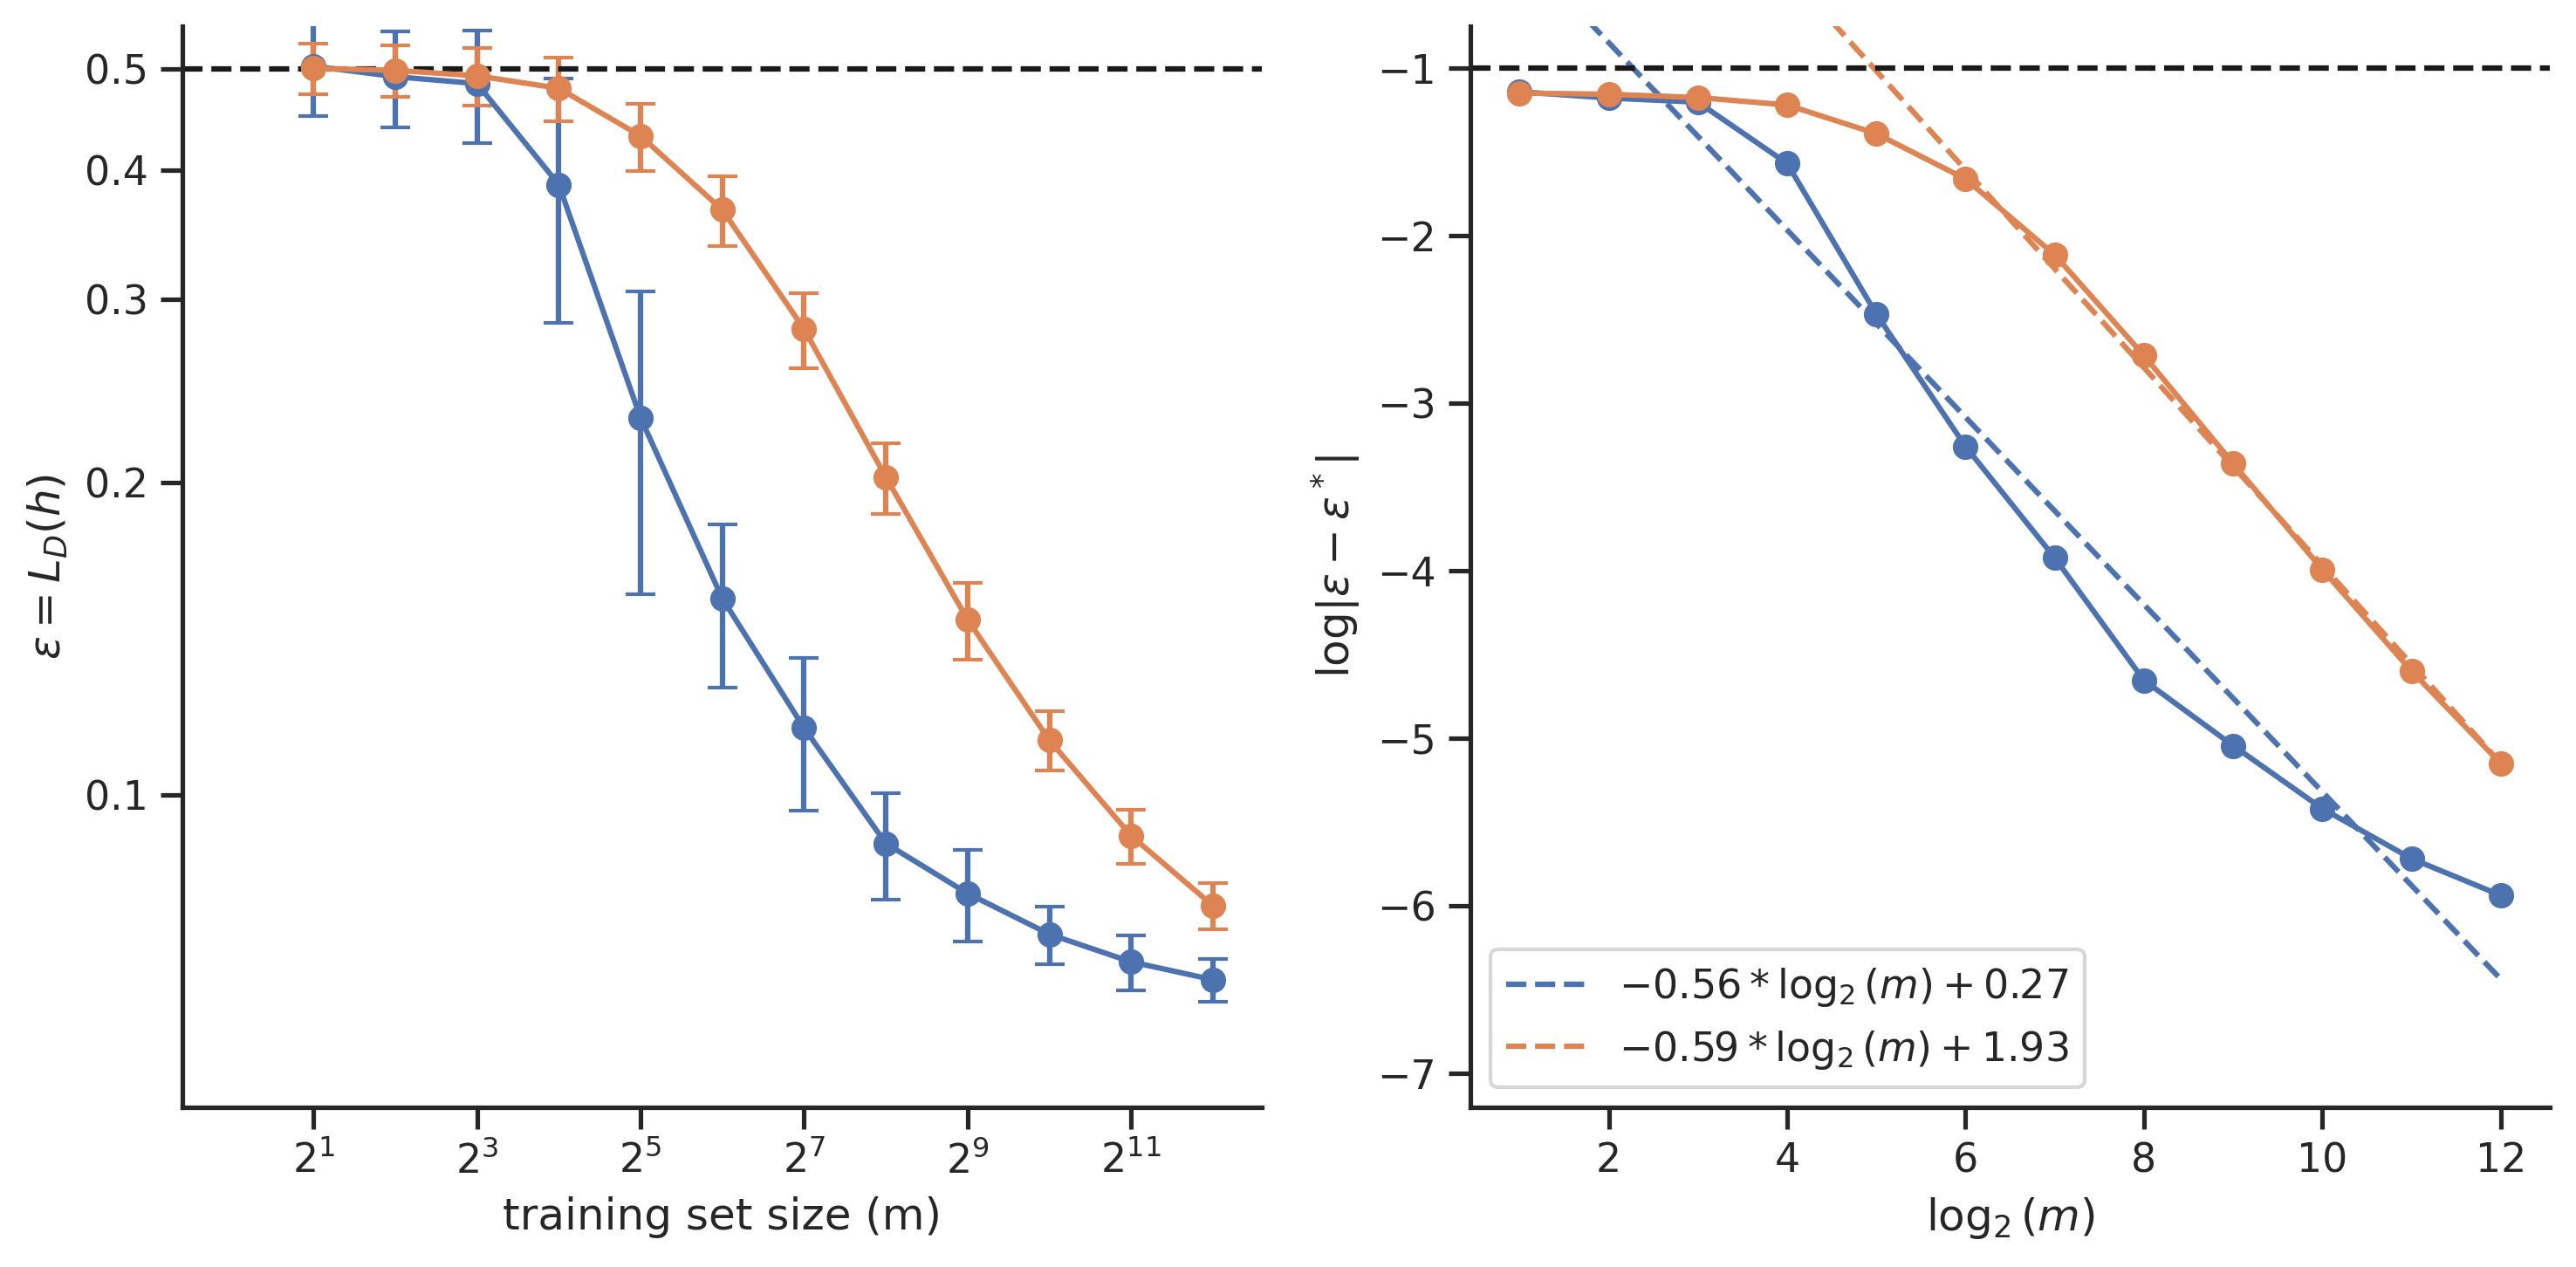

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

cc_linear.plot_error(axs[0])
cc_linear.plot_gap(axs[1], piecewise=True)

cc_poly.plot_error(axs[0])
cc_poly.plot_gap(axs[1], piecewise=True)

axs[0].axhline(y=0.5, color='k', linestyle='--')
axs[1].axhline(y=-1, color='k', linestyle='--')
axs[0].set_ylim([0.05, 0.55])
axs[1].set_ylim([-7.2, -0.75])

plt.tight_layout()
plt.savefig('./l1_curves.pdf', bbox_inches='tight')
plt.show()